# NFF5 PR3 — Brandon | Standardized three-coil optimization — student execution notebook
**Purpose:** Combine Rafael's three verified anatomical FEM vector bases without rerunning FEM. Compare equal allocation, optimized allocation, individual coils and full nominal drive against Cortney's pinned D70 reference.

**Execution:** SimNIBS 4.6 kernel → Restart Kernel and Run All Cells. Outputs go to a new timestamped Brandon directory. Source meshes remain read-only. Numerical checks are automatic; visual review remains a separate task.

**Scope:** computational proof of concept, not a validated stimulator or clinical safety assessment. The upstream manifest records visual review as pending.

**Revision 3:** matched target-centered anatomical sections, common scales, signed difference slices and Aaron export index. No additional FEM solves.

## 1 — Set your local paths (start here, Brandon)
You are using the verified PR3 workflow, not developing a new optimizer. Download the supplied Dropbox folder locally (make files available offline). Open this notebook from that folder in the SimNIBS 4.6.0 Jupyter kernel.

**Only edit the path settings at the top of the next code cell.**

- `ROOT`: folder containing this notebook and the supplied `inputs` folder. The default is the current Jupyter working directory. If it is different, replace `Path.cwd()` with `Path(r"C:\your\local\Brandon_PR3")`.
- `RUN`: folder containing `PR3_Rafael_handoff.json` and the `P1`, `P2`, `P3` mesh subfolders. Leave the default if you retain the supplied layout.
- `HEAD_DIR`: **change this to your local `m2m_ernie` folder**, containing `ernie.msh` and the MNI-to-subject transformation files. Use the identical verified Ernie model, not a newly generated mesh.
- `COIL_FILE`: supplied Cortney `.tcd` file; leave the default unless you store it elsewhere.
- `OUTPUT_ROOT`: where your timestamped results will be saved. Leave the default to keep them under your own `data` folder.
- `D70_MESH`: optional; leave `None` for the standard run. The numerical D70 benchmark is already in Rafael's manifest. Only set this to an existing verified D70 mesh if additional anatomical comparison is desired.

The manifest contains Victor's original absolute paths for provenance. Do not edit the JSON: the code uses the mesh basenames and your local `RUN` folder. Keep the P1/P2/P3 folders intact. No new FEM simulations are needed.

After configuring paths, choose **Kernel → Restart Kernel and Run All Cells**. Review the integrity checks, optimizer feasibility, plots and final handoff. Do not bypass a failed hash check. The 10-turn coil uses 207.3 MA/s at nominal 86 J per coil; all original numerical settings are retained.

<details><summary>Expected folder layout</summary>

```text
Brandon_PR3/
  NFF5_Brandon_PR3_Student.ipynb
  inputs/
    PR3_Rafael_handoff.json
    NFF5_CORT_C01_N10_EB86.tcd
    P1/  [original Rafael P1 scalar.msh]
    P2/  [original Rafael P2 scalar.msh]
    P3/  [original Rafael P3 scalar.msh]
  data/  [created automatically]
```
The Ernie model can remain in your existing SimNIBS installation. Gmsh Python bindings, a working graphical desktop/OpenGL environment, Pillow, NumPy, SciPy, pandas and Matplotlib are required for the existing workflow.
</details>

In [1]:
from pathlib import Path
import json, hashlib, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution, NonlinearConstraint
import simnibs
from simnibs import mesh_io, transformations
# ===== LOCAL PATH SETTINGS — edit here only =====
ROOT = Path.cwd().resolve()
RUN = ROOT
HEAD_DIR = Path(r"C:\Users\gothi\Documents\EEE488_CAPSTONE\simnibs4_examples\m2m_ernie")
COIL_FILE = RUN / 'NFF5_CORT_C01_N10_EB86.tcd'
OUTPUT_ROOT = ROOT / 'data'
D70_MESH = None  # optional Path(r"C:\...\verified_D70.msh")
# ===== END LOCAL PATH SETTINGS =====
MANIFEST = RUN / 'PR3_Rafael_handoff.json'
for label, path in [('RUN manifest', MANIFEST), ('HEAD_DIR head mesh', HEAD_DIR/'ernie.msh'), ('COIL_FILE', COIL_FILE)]:
    if not path.is_file():
        raise FileNotFoundError(f'{label}: {path} — check the local path settings above.')
h = json.loads(MANIFEST.read_text())
def sha(p):
    with open(p,'rb') as f:
        digest=hashlib.sha256()
        for chunk in iter(lambda:f.read(1024*1024),b''): digest.update(chunk)
    return digest.hexdigest()
assert simnibs.__version__ == h['simnibs_version'] == '4.6.0'
assert h['mesh_compatibility']=='PASS'
assert h['coil_id']=='NFF5_CORT_C01_N10_EB86'
assert sha(HEAD_DIR/'ernie.msh')==h['head_sha256']
assert sha(COIL_FILE)==h['coil_sha256']
DIDT=float(h['didt_A_per_s']); D70=float(h['d70_mean']); ENERGY=float(h['nominal_per_coil_energy_J'])
assert np.isclose(DIDT,207.3e6) and np.isclose(ENERGY,86) and np.isclose(h['nominal_system_energy_J'],258)
assert D70>0
NAMES=('P1','P2','P3'); records={r['position']:r for r in h['results']}
assert set(records)==set(NAMES)
for k in NAMES:
    p=h['placements'][k]
    assert p['clearance_lower_bound_mm']>=4 and np.isclose(p['axis_dot_outward'],-1) and p['tilt_deg']<0.01
MESH_PATHS={k:RUN/k/Path(records[k]['mesh'].replace('\\','/')).name for k in NAMES}
OUTPUT=OUTPUT_ROOT/('verified_'+datetime.datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
PLOTS=OUTPUT/'plots'
TARGET_MNI=np.array([-38.,44.,26.]); ROI_RADIUS_MM=float(h['roi_radius_mm']); assert ROI_RADIUS_MM==10
SEED=488; MAX_SUM=1.5; SURFACE_LIMIT_RATIO=1.10
print('Pinned run:',RUN,'\nD70:',D70,'\nVisual review:',h['visual_review'])

Pinned run: C:\Users\gothi\Documents\EEE488_CAPSTONE\ricn\PR3 
D70: 108.14961957680573 
Visual review: PENDING


## 2 — Source integrity gate
Verify each mesh against Rafael’s SHA-256 digest. A filename alone does not establish provenance. Stop on any mismatch.

In [2]:
paths = {}
for name, path in MESH_PATHS.items():
    if not path.is_file():
        raise FileNotFoundError(f"{name}: mesh file not found: {path}\nCheck RUN and the original {name} subfolder and filename in Section 1.")
    if path.suffix.lower() != '.msh':
        raise ValueError(f"{name}: expected a .msh file: {path}")
    paths[name] = path
    print(f"PASS {name}: {path}")

for k,p in paths.items():
    assert sha(p)==records[k]['mesh_sha256'], f'{k}: hash mismatch'
print('PASS: all source hashes')

PASS P1: C:\Users\gothi\Documents\EEE488_CAPSTONE\ricn\PR3\P1\ernie_TMS_1-0001_NFF5_CORT_C01_N10_EB86_scalar.msh
PASS P2: C:\Users\gothi\Documents\EEE488_CAPSTONE\ricn\PR3\P2\ernie_TMS_1-0001_NFF5_CORT_C01_N10_EB86_scalar.msh
PASS P3: C:\Users\gothi\Documents\EEE488_CAPSTONE\ricn\PR3\P3\ernie_TMS_1-0001_NFF5_CORT_C01_N10_EB86_scalar.msh
PASS: all source hashes


## 3 — Element-wise compatibility
Verify node IDs, coordinates, element IDs, tissue tags (both), types and connectivity before adding vectors. The scalar mesh filename is historical: the required element field is E with three Cartesian components in V/m. Reject missing or nonfinite vectors.

In [3]:
meshes={k:mesh_io.read_msh(str(v)) for k,v in paths.items()}
ref=meshes['P1']
xyz=np.asarray(ref.nodes.node_coord,float)
conn=np.asarray(ref.elm.node_number_list)
types=np.asarray(ref.elm.elm_type)
tags=np.asarray(ref.elm.tag1)
fields=[]
for name in NAMES:
    mesh=meshes[name]
    if not np.array_equal(np.asarray(mesh.elm.elm_type),types) or not np.array_equal(np.asarray(mesh.elm.tag1),tags):
        raise RuntimeError(f'{name}: element types/tags differ')
    if not np.array_equal(np.asarray(mesh.elm.node_number_list),conn):
        raise RuntimeError(f'{name}: connectivity differs')
    if not np.allclose(np.asarray(mesh.nodes.node_coord,float),xyz,atol=1e-7,rtol=0):
        raise RuntimeError(f'{name}: node coordinates differ')
    for obj,attr in [('nodes','node_number'),('elm','elm_number'),('elm','tag2')]:
        assert np.array_equal(getattr(getattr(mesh,obj),attr),getattr(getattr(ref,obj),attr)), (name,attr)
    matches=[f for f in mesh.elmdata if f.field_name=='E']
    if len(matches)!=1: raise RuntimeError(f'{name}: expected one element E field, found {len(matches)}')
    e=np.asarray(matches[0].value,float)
    if e.shape!=(len(types),3) or not np.all(np.isfinite(e)):
        raise RuntimeError(f'{name}: invalid E shape/values {e.shape}')
    fields.append(e)
E=np.stack(fields,axis=0)
print('PASS: aligned E basis', E.shape, 'V/m per Rafael reference excitation')

PASS: aligned E basis (3, 5576894, 3) V/m per Rafael reference excitation


## 4 — Anatomical measurement regions
Use the same MNI target and 10 mm GM sphere as Rafael. Tetrahedral centroids determine membership; volume weighting prevents dense mesh regions from dominating the mean. Off-target GM is all GM outside the sphere. The PR2 surface metric is retained as a **scalp tissue mean (tag 5)**, not a superficial cortical band or safety threshold. Verify the ROI count, volume and target against the handoff.

In [4]:
target_subject=np.asarray(transformations.mni2subject_coords(TARGET_MNI.reshape(1,3),str(HEAD_DIR)),float).reshape(3)
tet=(types==4)
idx=np.flatnonzero(tet)
vertices=xyz[conn[idx,:4]-1]
centers=vertices.mean(axis=1)
vol=np.abs(np.einsum('ij,ij->i',vertices[:,1]-vertices[:,0],np.cross(vertices[:,2]-vertices[:,0],vertices[:,3]-vertices[:,0])))/6
if not np.all(vol>0): raise RuntimeError('Nonpositive tetrahedral volumes')
mask_target=(tags[idx]==2)&(np.linalg.norm(centers-target_subject,axis=1)<=ROI_RADIUS_MM)
mask_other=(tags[idx]==2)&~mask_target
mask_surface=(tags[idx]==5)
for label,mask in [('target',mask_target),('other gray matter',mask_other),('scalp proxy',mask_surface)]:
    if not mask.any():raise RuntimeError(f'Empty region: {label}; check tissue tags')
    print(label, int(mask.sum()),'tetrahedra')
E_tet=E[:,idx,:]
print('Target subject coordinates:',target_subject)
np.testing.assert_allclose(target_subject,h["target"],atol=1e-5,rtol=0)
for r in records.values():
    assert mask_target.sum()==r["roi_count"]
    assert np.isclose(vol[mask_target].sum(),r["roi_volume_mm3"],rtol=1e-6)

target 4091 tetrahedra
other gray matter 1333476 tetrahedra
scalp proxy 565436 tetrahedra
Target subject coordinates: [-33.71040726  70.74802399  43.76509094]


## 5 — Vector superposition and normalization
$$\mathbf E_{total}(\mathbf r)=\sum_{i=1}^3 a_i\mathbf E_i(\mathbf r),\qquad |E|=\|\mathbf E_{total}\|_2$$
Each coefficient scales the reference current slew rate, not current itself. Add Cartesian vectors before taking magnitude. Nonnegative weights represent synchronized same-polarity excitation. The volume-weighted mean is $\sum V_j|E_j|/\sum V_j$. D70 percentage is 100 times target mean divided by 108.1496 V/m. No extra multiplication by turn count or slew rate is required: both are already represented in the FEM bases.

In [5]:
def field_magnitude(a):
    a=np.asarray(a,float)
    if a.shape!=(3,): raise ValueError('Expected 3 coefficients')
    return np.linalg.norm(np.einsum('k,kij->ij',a,E_tet),axis=1)

def roi_mean(magnitude,mask):
    return float(np.average(magnitude[mask],weights=vol[mask]))

def metrics(a):
    mag=field_magnitude(a)
    return {'target':roi_mean(mag,mask_target), 'surface':roi_mean(mag,mask_surface), 'offtarget':roi_mean(mag,mask_other)}

for k in range(3):
    a=np.eye(3)[k]
    print(NAMES[k],metrics(a))
for k,name in enumerate(NAMES):
    assert np.isclose(metrics(np.eye(3)[k])["target"],records[name]["mean_E_V_per_m"],rtol=1e-6), name
print("PASS: Rafael target means reproduced")

P1 {'target': 21.878651138949145, 'surface': 2.583094523539027, 'offtarget': 3.1866608223532276}
P2 {'target': 22.496348639318423, 'surface': 2.641177725575661, 'offtarget': 2.7234053154911297}
P3 {'target': 21.654482053228232, 'surface': 2.8986159791173987, 'offtarget': 3.267868725058238}
PASS: Rafael target means reproduced


## 6 — Controlled optimization and full-drive comparison
Retain Brandon's PR2 equal-weight baseline (0.5, 0.5, 0.5), fixed sum 1.5, individual bounds [0,1], and scalp cap 110% of baseline. Minimize negative normalized target mean plus 0.20 times normalized off-target mean. Enforce the scalp cap explicitly. Differential evolution is stochastic; the fixed seed supports reproducibility, not proof of global optimality.

Also evaluate (1,1,1), which uses the full nominal three-channel allocation. Under an assumed identical pulse shape, duration and inductance, energy scales approximately as $86\sum a_i^2$ J. This is a screening proxy, not measured energy; mutual inductance and driver losses are omitted. The fixed-sum cases are **not energy matched** to one another or D70. Full drive is a separate unconstrained comparison, not a candidate subject to the PR2 scalp cap.

In [6]:
BASELINE = np.array([0.5, 0.5, 0.5])
base = metrics(BASELINE)
SURFACE_CAP = base['surface'] * SURFACE_LIMIT_RATIO
print('Equal-weight baseline:', base)
print('Exploratory surface cap:', SURFACE_CAP)

def unpack(x):
    """Two independent variables; exact total allocation MAX_SUM."""
    return np.array([x[0], x[1], MAX_SUM - x[0] - x[1]])

def feasible(a):
    a = np.asarray(a, dtype=float)
    return (a.shape == (3,) and np.all(a >= -1e-9)
            and np.all(a <= 1 + 1e-9)
            and abs(a.sum() - MAX_SUM) <= 1e-8
            and metrics(a)['surface'] <= SURFACE_CAP + 1e-9)

def objective(x):
    a = unpack(x)
    if np.any(a < 0) or np.any(a > 1):
        return 1e4 + 1e3 * np.sum(np.maximum(-a, 0) + np.maximum(a-1, 0))
    m = metrics(a)
    # Favor the target while penalizing off-target exposure and surface-cap violations.
    return (-m['target']/base['target']
            + 0.20*m['offtarget']/base['offtarget']
            + 1e3*max(0.,m['surface']/SURFACE_CAP-1.)**2)


Equal-weight baseline: {'target': 10.79941952454329, 'surface': 3.7343797241996666, 'offtarget': 4.421858088631412}
Exploratory surface cap: 4.107817696619634


In [7]:
constraint=NonlinearConstraint(lambda x: [unpack(x)[2], metrics(unpack(x))["surface"]], [0,0], [1,SURFACE_CAP])
res=differential_evolution(objective,[(0,1),(0,1)],constraints=(constraint,),seed=SEED,popsize=12,maxiter=120,tol=1e-7,polish=True)
optimal=unpack(res.x)
if not feasible(optimal): raise RuntimeError(f'Optimizer returned infeasible result: {optimal}, {metrics(optimal)}')
rows=[]
for label,a in [('equal_budget',BASELINE),('optimized',optimal),('full_nominal',np.ones(3)),('P1_only',np.array([1.,0,0])),('P2_only',np.array([0,1.,0])),('P3_only',np.array([0,0,1.]))]:
    rows.append({'candidate':label,**{f'a{i+1}':float(a[i]) for i in range(3)},'sum_a':float(sum(a)),**metrics(a)})
comparison=pd.DataFrame(rows)
print('Optimization:',res.message)
print(comparison.to_string(index=False))
comparison['percent_D70']=100*comparison.target/D70
comparison['nominal_energy_proxy_J']=ENERGY*(comparison[['a1','a2','a3']]**2).sum(axis=1)
comparison['target_to_offtarget']=comparison.target/comparison.offtarget
print(comparison.to_string(index=False))
print('Optimized target change vs equal (%):',100*(metrics(optimal)['target']/base['target']-1))

c:\Users\gothi\SimNIBS-4.6\simnibs_env\Lib\site-packages\scipy\optimize\_differentiable_functions.py:385: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)
c:\Users\gothi\SimNIBS-4.6\simnibs_env\Lib\site-packages\scipy\optimize\_differentiable_functions.py:737: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(delta_x, delta_g)


Optimization: Optimization terminated successfully.
   candidate  a1  a2           a3  sum_a    target  surface  offtarget
equal_budget 0.5 0.5 5.000000e-01    1.5 10.799420 3.734380   4.421858
   optimized 0.5 1.0 1.110543e-08    1.5 21.773452 3.752803   4.190081
full_nominal 1.0 1.0 1.000000e+00    3.0 21.598839 7.468759   8.843716
     P1_only 1.0 0.0 0.000000e+00    1.0 21.878651 2.583095   3.186661
     P2_only 0.0 1.0 0.000000e+00    1.0 22.496349 2.641178   2.723405
     P3_only 0.0 0.0 1.000000e+00    1.0 21.654482 2.898616   3.267869
   candidate  a1  a2           a3  sum_a    target  surface  offtarget  percent_D70  nominal_energy_proxy_J  target_to_offtarget
equal_budget 0.5 0.5 5.000000e-01    1.5 10.799420 3.734380   4.421858     9.985629               64.500000             2.442281
   optimized 0.5 1.0 1.110543e-08    1.5 21.773452 3.752803   4.190081    20.132712              107.499998             5.196427
full_nominal 1.0 1.0 1.000000e+00    3.0 21.598839 7.468759   8.

## 7 — Numerical verification
Independently recompute each unit-weight regional mean directly from its basis. Check zero excitation and half-amplitude linearity. These tests establish indexing and algebra consistency, not independent validation of the FEM physics.

In [8]:

# Independent single-coil limiting-case validation
# No FEM reruns. Original datasets remain unchanged.

regions = {
    "target": mask_target,
    "surface": mask_surface,
    "offtarget": mask_other
}

# Extract tetrahedral fields from the full FEM basis.
E_tet = E[:, tet, :]

for k, name in enumerate(NAMES):
    weights = np.eye(3)[k]
    calculated = metrics(weights)

    print(f"\n{name} validation:")

    for region, mask in regions.items():

        # Region masks already index the tetrahedral subset.
        original_E = np.linalg.norm(
            E_tet[k, mask, :], axis=1
        )

        reference = np.average(
            original_E,
            weights=vol[mask]
        )

        error = abs(calculated[region] - reference)

        print(
            f"  {region}: calculated={calculated[region]:.8f}, "
            f"reference={reference:.8f}, "
            f"error={error:.2e}"
        )

        assert np.isclose(
            calculated[region],
            reference,
            rtol=1e-10,
            atol=1e-12
        )

print("\nPASS: All three single-coil limiting cases.")



P1 validation:
  target: calculated=21.87865114, reference=21.87865114, error=0.00e+00
  surface: calculated=2.58309452, reference=2.58309452, error=0.00e+00
  offtarget: calculated=3.18666082, reference=3.18666082, error=0.00e+00

P2 validation:
  target: calculated=22.49634864, reference=22.49634864, error=0.00e+00
  surface: calculated=2.64117773, reference=2.64117773, error=0.00e+00
  offtarget: calculated=2.72340532, reference=2.72340532, error=0.00e+00

P3 validation:
  target: calculated=21.65448205, reference=21.65448205, error=0.00e+00
  surface: calculated=2.89861598, reference=2.89861598, error=0.00e+00
  offtarget: calculated=3.26786873, reference=3.26786873, error=0.00e+00

PASS: All three single-coil limiting cases.


In [9]:

# Final superposition identity checks
# Uses existing FEM data only. No new simulations.

zero = metrics(np.array([0.0, 0.0, 0.0]))
full = metrics(np.array([1.0, 0.0, 0.0]))
half = metrics(np.array([0.5, 0.0, 0.0]))

for region in ("target", "surface", "offtarget"):
    assert np.isclose(zero[region], 0.0, atol=1e-12)
    assert np.isclose(
        half[region], 0.5 * full[region],
        rtol=1e-10, atol=1e-12
    )
    print(
        f"{region}: zero={zero[region]:.8f}, "
        f"half={half[region]:.8f}, "
        f"expected={0.5 * full[region]:.8f}"
    )

print("\nPASS: Zero-field and linear-scaling identities.")


target: zero=0.00000000, half=10.93932557, expected=10.93932557
surface: zero=0.00000000, half=1.29154726, expected=1.29154726
offtarget: zero=0.00000000, half=1.59333041, expected=1.59333041

PASS: Zero-field and linear-scaling identities.


## 8 — Report-ready results and provenance
Export all candidates, regional means, D70 percentages, nominal energy proxy and target/off-target ratio. Compare target performance with the D70 benchmark and inspect ROI distributions on common bins. The D70 reference is a target mean only; do not infer its off-target or scalp exposure from this notebook.

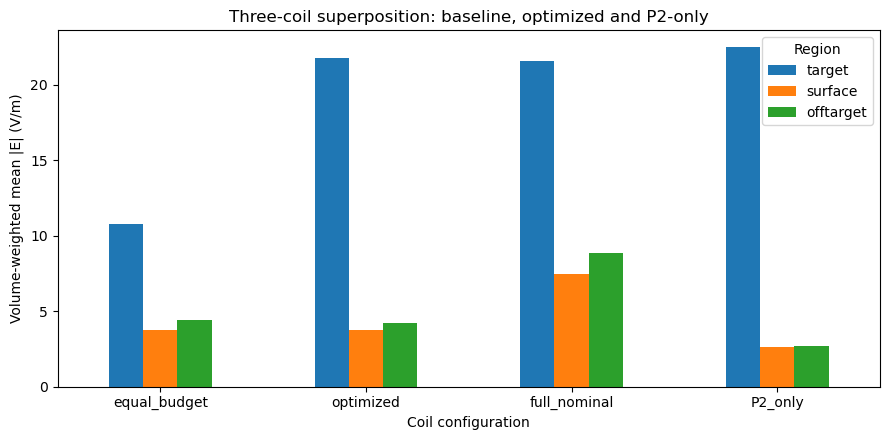

Saved CSV: C:\Users\gothi\Documents\EEE488_CAPSTONE\ricn\PR3\data\verified_20261126_182522_328531\brandon_fem_candidate_comparison.csv
Saved graph: C:\Users\gothi\Documents\EEE488_CAPSTONE\ricn\PR3\data\verified_20261126_182522_328531\plots\brandon_fem_roi_comparison.png
Saved JSON: C:\Users\gothi\Documents\EEE488_CAPSTONE\ricn\PR3\data\verified_20261126_182522_328531\brandon_fem_optimization_provenance.json


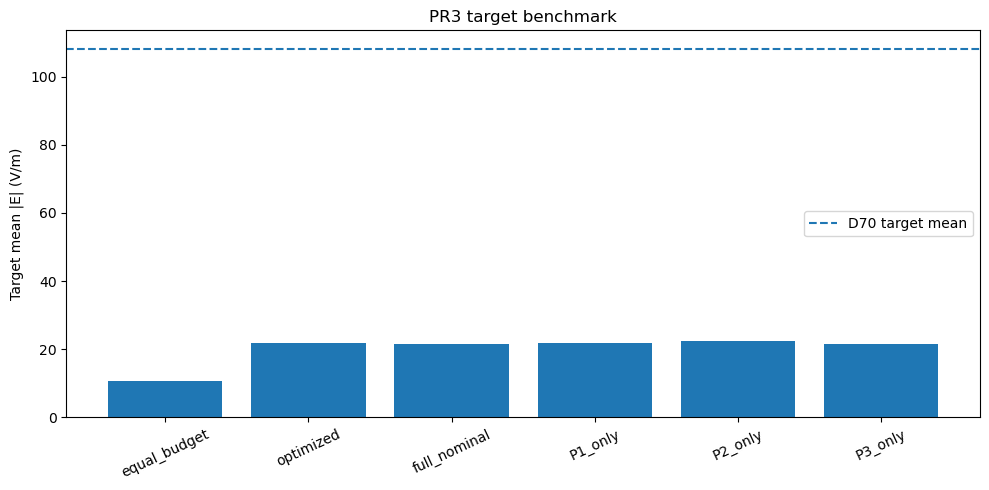

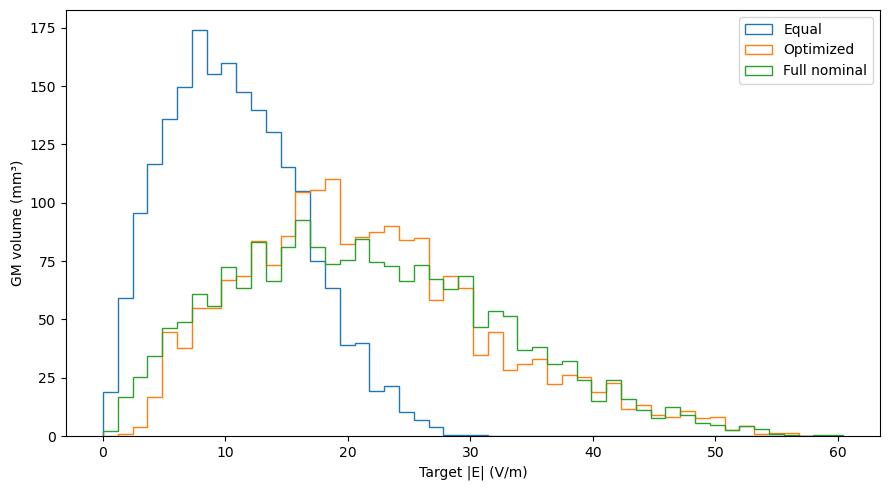

In [10]:
OUTPUT.mkdir(parents=True, exist_ok=True)
PLOTS.mkdir(parents=True, exist_ok=True)
comparison.to_csv(OUTPUT / 'brandon_fem_candidate_comparison.csv', index=False)
labels = ['equal_budget', 'optimized', 'full_nominal', 'P2_only']
plot_data = comparison.set_index('candidate').loc[labels, ['target', 'surface', 'offtarget']]
ax = plot_data.plot(kind='bar', figsize=(9, 4.5), rot=0)
ax.set_ylabel('Volume-weighted mean |E| (V/m)')
ax.set_xlabel('Coil configuration')
ax.set_title('Three-coil superposition: baseline, optimized and P2-only')
ax.legend(title='Region')
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(PLOTS / 'brandon_fem_roi_comparison.png', dpi=180)
plt.show()
record = {
    'rafael_manifest': str(MANIFEST), 'rafael_manifest_sha256': sha(MANIFEST), 'upstream_visual_review': h['visual_review'], 'd70_mean_V_per_m': D70, 'nominal_per_coil_energy_J': ENERGY, 'input_mesh_hashes': {k:records[k]['mesh_sha256'] for k in NAMES}, 'input_meshes': {k: str(v) for k, v in paths.items()},
    'target_mni_mm': TARGET_MNI.tolist(),
    'target_subject_mm': target_subject.tolist(),
    'roi_radius_mm': ROI_RADIUS_MM,
    'reference_didt_A_per_s': DIDT,
    'baseline_weights': BASELINE.tolist(),
    'optimized_weights': optimal.tolist(),
    'normalized_three_coil_budget': MAX_SUM,
    'surface_cap_ratio_to_baseline': SURFACE_LIMIT_RATIO,
    'optimizer_seed': SEED,
    'optimizer_success': bool(res.success),
    'optimizer_feasible': bool(feasible(optimal)),
    'source': 'Rafael three-position FEM datasets; Brandon student execution',
    'constraints_exploratory': True,
    'single_coil_comparisons_not_budget_matched': True
}
(OUTPUT / 'brandon_fem_optimization_provenance.json').write_text(json.dumps(record, indent=2), encoding='utf-8')
print('Saved CSV:', OUTPUT / 'brandon_fem_candidate_comparison.csv')
print('Saved graph:', PLOTS / 'brandon_fem_roi_comparison.png')
print('Saved JSON:', OUTPUT / 'brandon_fem_optimization_provenance.json')
fig,ax=plt.subplots(figsize=(10,5))
ax.bar(comparison.candidate,comparison.target); ax.axhline(D70,ls='--',label='D70 target mean')
ax.set(ylabel='Target mean |E| (V/m)',title='PR3 target benchmark'); ax.tick_params(axis='x',rotation=25); ax.legend(); fig.tight_layout(); fig.savefig(PLOTS/'target_D70.png',dpi=180); plt.show()
fig,ax=plt.subplots(figsize=(9,5))
candidates={'Equal':BASELINE,'Optimized':optimal,'Full nominal':np.ones(3)}
roi_fields={k:field_magnitude(a)[mask_target] for k,a in candidates.items()}
bins=np.linspace(0,max(v.max() for v in roi_fields.values()),51)
for k,v in roi_fields.items(): ax.hist(v,bins=bins,weights=vol[mask_target],histtype='step',label=k)
ax.set(xlabel='Target |E| (V/m)',ylabel='GM volume (mm³)'); ax.legend(); fig.tight_layout(); fig.savefig(PLOTS/'target_histograms.png',dpi=180); plt.show()

## 9 — PR3 interpretation and handoff
Review optimizer convergence and feasibility separately. Compare optimized versus equal weights under the same normalized sum, then full nominal drive versus D70. Report target gain, scalp and off-target changes, and the energy proxy explicitly. A higher target mean alone does not establish improved focality or clinical efficacy. Inspect the plots and upstream geometry before declaring visual approval. Share the executed notebook, CSV, PNGs and JSON with Aaron and the team. No source FEM files are modified.

## 10 — Reconstruct and export full anatomical fields
Brandon now owns the downstream workflow formerly performed by Rafael in PR2. Apply the drive coefficients to every aligned element vector, not just the target ROI. The equal-budget and optimized cases share a coefficient sum of 1.5 (not necessarily equal magnetic energy); full nominal is a separate unconstrained reference. Each coefficient multiplies 207.3 MA/s. Linear superposition assumes fixed conductivity and prescribed simultaneous drive waveforms; mutual coupling and driver feasibility are not modeled. No additional FEM solve is needed. The signed difference is |E_opt| − |E_equal|, not the magnitude of the vector difference. Original meshes are never overwritten.

In [11]:
import gc
EXPORT_DIR=OUTPUT/'combined_fields'; EXPORT_DIR.mkdir(exist_ok=True)
weights_by_case={'equal_budget':BASELINE,'optimized':optimal,'full_nominal':np.ones(3),'P2_only':np.array([0.,1.,0.])}
output_files={}; magnitudes={}
for name,a in weights_by_case.items():
    field=np.einsum('i,ijk->jk',a,E)
    mag=np.linalg.norm(field,axis=1)
    np.testing.assert_allclose(np.average(mag[idx][mask_target],weights=vol[mask_target]),metrics(a)['target'],rtol=1e-7)
    m=mesh_io.read_msh(str(paths['P1']))
    m.elmdata=[]; m.nodedata=[]
    m.add_element_field(field,f'E_{name}')
    m.add_element_field(mag,f'magnE_{name}')
    dest=EXPORT_DIR/f'NFF5_PR3_{name}_E_visualization.msh'
    mesh_io.write_msh(m,str(dest)); output_files[name]=dest; magnitudes[name]=mag
    print(name, 'drive MA/s:',a*DIDT/1e6, 'saved:',dest)
    del m,field; gc.collect()
delta=magnitudes['optimized']-magnitudes['equal_budget']
m=mesh_io.read_msh(str(paths['P1'])); m.elmdata=[]; m.nodedata=[]
m.add_element_field(delta,'signed_magnitude_change_V_per_m')
dest=EXPORT_DIR/'NFF5_PR3_optimized_minus_equal_difference.msh'; mesh_io.write_msh(m,str(dest)); output_files['difference']=dest
del m; gc.collect()
# Optional commercial reference: use only an explicitly identified existing mesh.
if D70_MESH is not None:
    D70_MESH=Path(D70_MESH); m=mesh_io.read_msh(str(D70_MESH))
    assert any(f.field_name=='magnE' for f in m.elmdata)
    output_files['D70']=D70_MESH
    del m
print('Full anatomical exports complete.')

equal_budget drive MA/s: [103.65 103.65 103.65] saved: C:\Users\gothi\Documents\EEE488_CAPSTONE\ricn\PR3\data\verified_20261126_182522_328531\combined_fields\NFF5_PR3_equal_budget_E_visualization.msh
optimized drive MA/s: [1.03649999e+02 2.07299998e+02 2.30215571e-06] saved: C:\Users\gothi\Documents\EEE488_CAPSTONE\ricn\PR3\data\verified_20261126_182522_328531\combined_fields\NFF5_PR3_optimized_E_visualization.msh
full_nominal drive MA/s: [207.3 207.3 207.3] saved: C:\Users\gothi\Documents\EEE488_CAPSTONE\ricn\PR3\data\verified_20261126_182522_328531\combined_fields\NFF5_PR3_full_nominal_E_visualization.msh
P2_only drive MA/s: [  0.  207.3   0. ] saved: C:\Users\gothi\Documents\EEE488_CAPSTONE\ricn\PR3\data\verified_20261126_182522_328531\combined_fields\NFF5_PR3_P2_only_E_visualization.msh
Full anatomical exports complete.


## 11 — Automated cortical comparison (Chubby Baby Brain Squadron)
Reuse Rafael’s executed PR2 Gmsh camera and gray-matter extraction workflow. Render all absolute maps with the same global range; use a separate symmetric signed-difference range. The optional D70 panel is included only if its existing mesh is explicitly supplied. Increase camera scale modestly, crop identical outer margins across all panels, and use a tightly packed high-resolution figure. The individual native PNGs and full meshes remain available for alternative angles. Gmsh FLTK requires a working desktop/OpenGL context. If rendering fails, the numerical results and mesh exports above remain available. Inspect for clipping and readable scales before report use.

Extracting gray matter: Equal drive weights
Equal drive weights: 0.0082 to 64.3594 V/m
Extracting gray matter: Optimized drive weights
Optimized drive weights: 0.0056 to 68.8491 V/m
Extracting gray matter: Full nominal excitation
Full nominal excitation: 0.0165 to 128.7188 V/m
Extracting gray matter: P2 only
P2 only: 0.0035 to 54.3905 V/m
Extracting gray matter: Optimized minus equal
Optimized minus equal: -20.4036 to 35.8392 V/m

Common absolute scale: 0 to 128.7188 V/m
Difference scale: ±35.8392 V/m
Saved: NFF5_PR3_equal_budget.png
Saved: NFF5_PR3_optimized.png
Saved: NFF5_PR3_full_nominal.png
Saved: NFF5_PR3_P2_only.png
Saved: NFF5_PR3_difference.png


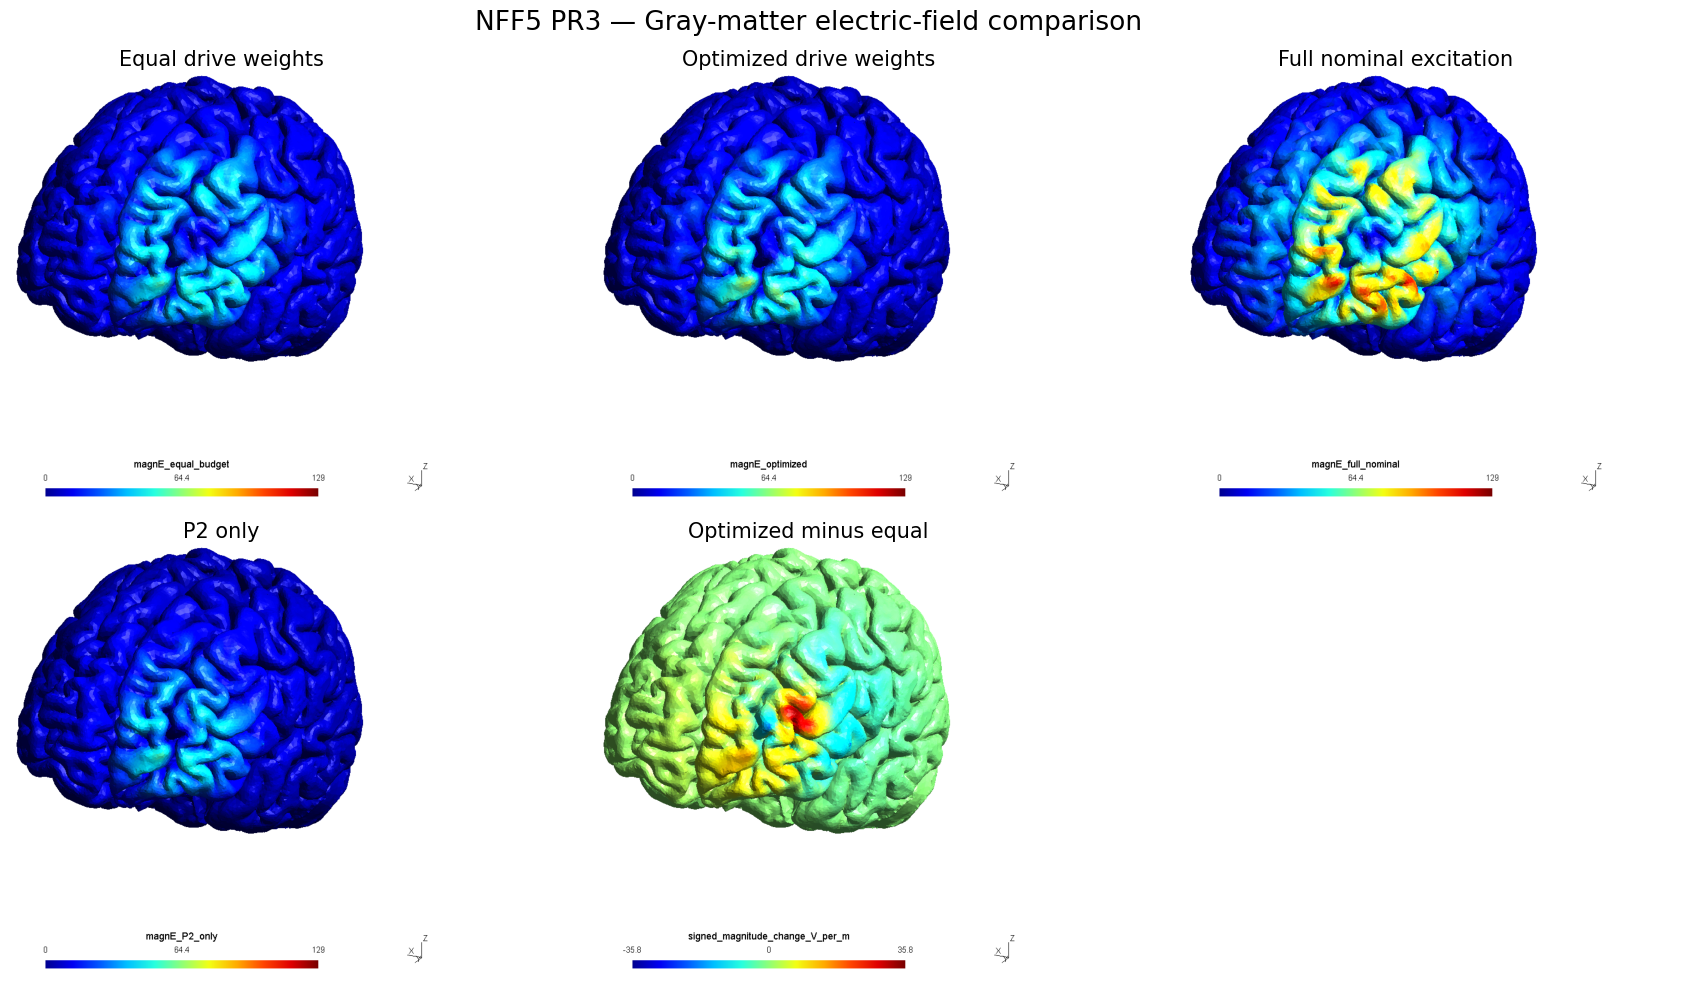

Saved: C:\Users\gothi\Documents\EEE488_CAPSTONE\ricn\PR3\data\verified_20261126_182522_328531\combined_fields\PR3_standardized_figures\NFF5_PR3_cortical_comparison.png


In [12]:
from pathlib import Path
import gc
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from simnibs import mesh_io
import gmsh

GM_DIR = EXPORT_DIR / "gray_matter_only"
FIG_DIR = EXPORT_DIR / "PR3_standardized_figures"

GM_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Define the four configurations and scalar fields
# ------------------------------------------------------------

CONFIGS=[dict(key=k,title=t,source=str(output_files[k]),field=f'magnE_{k}') for k,t in [('equal_budget','Equal drive weights'),('optimized','Optimized drive weights'),('full_nominal','Full nominal excitation'),('P2_only','P2 only')]]
if 'D70' in output_files:
    CONFIGS.append(dict(key='D70',title='D70 benchmark',source=str(output_files['D70']),field='magnE'))
CONFIGS.append(dict(key='difference',title='Optimized minus equal',source=str(output_files['difference']),field='signed_magnitude_change_V_per_m'))

# ------------------------------------------------------------
# 2. Camera coordinates captured from your Gmsh .opt file
# ------------------------------------------------------------

CAMERA = {
    "General.RotationX": 295.1984691036839,
    "General.RotationY": 350.133281950552,
    "General.RotationZ": 151.9897594083793,
    "General.ScaleX": 1.12,
    "General.ScaleY": 1.12,
    "General.ScaleZ": 1.12,
    "General.Orthographic": 1,
    "General.RotationCenterGravity": 1,
}

# ------------------------------------------------------------
# 3. Prepare/reuse gray-matter meshes and verify field data
# ------------------------------------------------------------

for config in CONFIGS:

    source = EXPORT_DIR / config["source"]
    target = GM_DIR / f"NFF5_PR3_{config['key']}_GM.msh"

    if not source.is_file():
        raise FileNotFoundError(source)

    # Only extract again if missing or outdated.
    if (
        not target.is_file()
        or target.stat().st_mtime < source.stat().st_mtime
    ):
        print("Extracting gray matter:", config["title"])

        original = mesh_io.read_msh(str(source))
        gm = original.crop_mesh(tags=[2])

        available = [f.field_name for f in gm.elmdata]

        if config["field"] not in available:
            raise RuntimeError(
                f"Missing field: {config['field']}"
            )

        mesh_io.write_msh(gm, str(target))

        del original, gm
        gc.collect()

    config["gm_file"] = target

    gm = mesh_io.read_msh(str(target))
    fields = {f.field_name: f for f in gm.elmdata}

    if config["field"] not in fields:
        raise RuntimeError(
            f"Missing field {config['field']} in {target.name}"
        )

    values = np.asarray(
        fields[config["field"]].value,
        dtype=float
    ).ravel()

    values = values[np.isfinite(values)]

    if values.size == 0:
        raise RuntimeError(
            f"No finite values for {config['title']}"
        )

    config["min"] = float(values.min())
    config["max"] = float(values.max())

    print(
        f"{config['title']}: "
        f"{config['min']:.4f} to "
        f"{config['max']:.4f} V/m"
    )

    del gm, fields, values
    gc.collect()

# ------------------------------------------------------------
# 4. Determine shared and signed-difference field ranges
# ------------------------------------------------------------

absolute_max = max(
    config["max"] for config in CONFIGS[:-1]
)

difference_limit = max(
    abs(CONFIGS[-1]["min"]),
    abs(CONFIGS[-1]["max"])
)

assert absolute_max > 0
difference_limit = max(difference_limit, 1e-9)

print(
    f"\nCommon absolute scale: "
    f"0 to {absolute_max:.4f} V/m"
)

print(
    f"Difference scale: "
    f"±{difference_limit:.4f} V/m"
)

# ------------------------------------------------------------
# 5. Render each cortical map in Gmsh
# ------------------------------------------------------------

def render_one(config):

    gmsh.clear()
    gmsh.open(str(config["gm_file"]))

    # Apply identical camera settings to all four maps.
    for option, value in CAMERA.items():
        gmsh.option.setNumber(option, value)

    gmsh.option.setNumber("General.Axes", 0)
    gmsh.option.setNumber("General.BackgroundGradient", 0)
    gmsh.option.setNumber("Mesh.SurfaceFaces", 0)
    gmsh.option.setNumber("Mesh.VolumeEdges", 0)

    view_tags = list(gmsh.view.getTags())

    # View option indices are zero-based.
    matching = [
        index
        for index in range(len(view_tags))
        if gmsh.option.getString(f"View[{index}].Name")
        == config["field"]
    ]

    if len(matching) != 1:
        raise RuntimeError(
            f"Expected one view named {config['field']}; "
            f"found {len(matching)}"
        )

    selected = matching[0]

    # Disable all other postprocessing fields.
    for index in range(len(view_tags)):
        gmsh.option.setNumber(
            f"View[{index}].Visible", 0
        )

    gmsh.option.setNumber(
        f"View[{selected}].Visible", 1
    )

    gmsh.option.setNumber(
        f"View[{selected}].ShowScale", 1
    )

    gmsh.option.setNumber(
        f"View[{selected}].RangeType", 2
    )

    if config["key"] == "difference":
        lower = -difference_limit
        upper = difference_limit
        palette = 11
    else:
        lower = 0.0
        upper = absolute_max
        palette = 2

    gmsh.option.setNumber(
        f"View[{selected}].ColorTableNumber", palette
    )

    gmsh.option.setNumber(
        f"View[{selected}].CustomMin", lower
    )

    gmsh.option.setNumber(
        f"View[{selected}].CustomMax", upper
    )

    output = FIG_DIR / f"NFF5_PR3_{config['key']}.png"

    gmsh.write(str(output))

    if not output.is_file():
        raise RuntimeError(
            f"Gmsh did not create {output.name}"
        )

    print("Saved:", output.name, flush=True)

    return output

# ------------------------------------------------------------
# 6. Generate all four PNGs
# ------------------------------------------------------------

gmsh.initialize()

try:
    gmsh.option.setNumber("General.Terminal", 1)
    gmsh.option.setNumber("General.GraphicsWidth", 1200)
    gmsh.option.setNumber("General.GraphicsHeight", 950)
    gmsh.fltk.initialize()

    for config in CONFIGS:
        config["png"] = render_one(config)

finally:
    gmsh.finalize()

# ------------------------------------------------------------
# 7. Assemble the four-map comparison panel
# ------------------------------------------------------------

# Common crop: preserve every nonwhite pixel in every panel, including scales.
from PIL import ImageChops
images=[]; bounds=[]
for config in CONFIGS:
    with Image.open(config['png']) as im:
        rgb=im.convert('RGB'); images.append(rgb)
        bg=Image.new('RGB',rgb.size,rgb.getpixel((0,0)))
        box=ImageChops.difference(rgb,bg).convert('L').point(lambda p: 255 if p>12 else 0).getbbox()
        bounds.append(box or (0,0,*rgb.size))
if len({im.size for im in images})==1:
    W,H=images[0].size; pad=12
    crop=(max(0,min(b[0] for b in bounds)-pad),max(0,min(b[1] for b in bounds)-pad),min(W,max(b[2] for b in bounds)+pad),min(H,max(b[3] for b in bounds)+pad))
    images=[im.crop(crop) for im in images]
fig,axes=plt.subplots(2,3,figsize=(18,10),facecolor='white')
for ax in axes.flat: ax.axis('off')
for ax,config,im in zip(axes.flat,CONFIGS,images):
    ax.imshow(im); ax.set_title(config['title'],fontsize=15,pad=3)
fig.suptitle('NFF5 PR3 — Gray-matter electric-field comparison',fontsize=19)
fig.subplots_adjust(left=.015,right=.985,bottom=.015,top=.92,wspace=.025,hspace=.09)
panel_path=FIG_DIR/'NFF5_PR3_cortical_comparison.png'
fig.savefig(panel_path,dpi=300,bbox_inches='tight',pad_inches=.06)
plt.show(); plt.close(fig)
print('Saved:',panel_path)


## 12 — Target-centered anatomical slice heatmaps

Intersect the original gray-matter tetrahedra with the axial (z), coronal (y), and sagittal (x) planes through the verified subject-space DLPFC center. Each intersection polygon is colored by its parent tetrahedron’s field magnitude; this avoids interpolation across tissue boundaries or extrapolation into empty space. White background outside gray matter is masked anatomy, not zero field. These are GM-only anatomical sections, not MRI overlays or whole-brain tissue maps.

All absolute maps use the **same 0-to-maximum V/m range as the cortical squadron**, with no per-panel autoscaling. The signed difference is $|E_{opt}|-|E_{equal}|$, not the magnitude of the vector difference. Its range is symmetric about zero and shared with the cortical difference map. Red means enhancement, blue reduction. The circle marks the intersection of the 10 mm target sphere with each central plane. Coordinates are Ernie subject-space millimeters; the axes are not radiological display conventions.

The equal and optimized cases share a fixed sum of drive coefficients, not necessarily equal energy. The nominal energy proxy is reported separately. The D70 slice row is included only if a verified, geometrically compatible reference mesh is supplied; otherwise its numerical benchmark remains available.

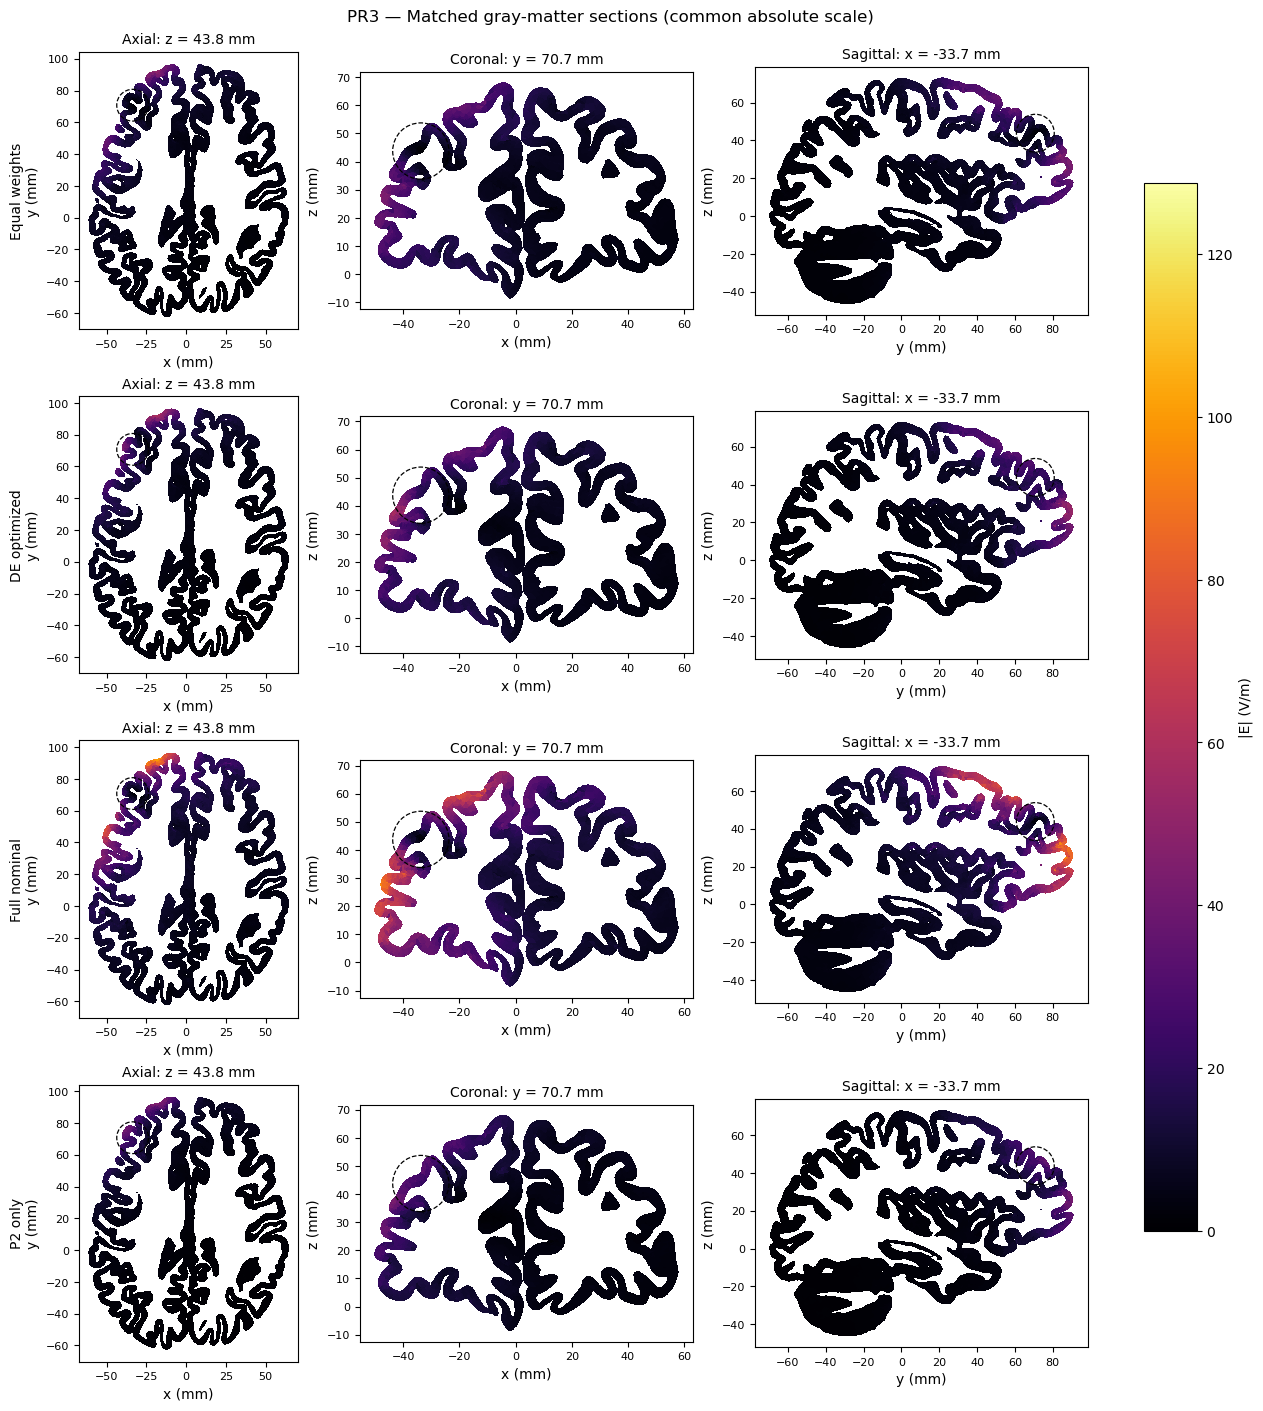

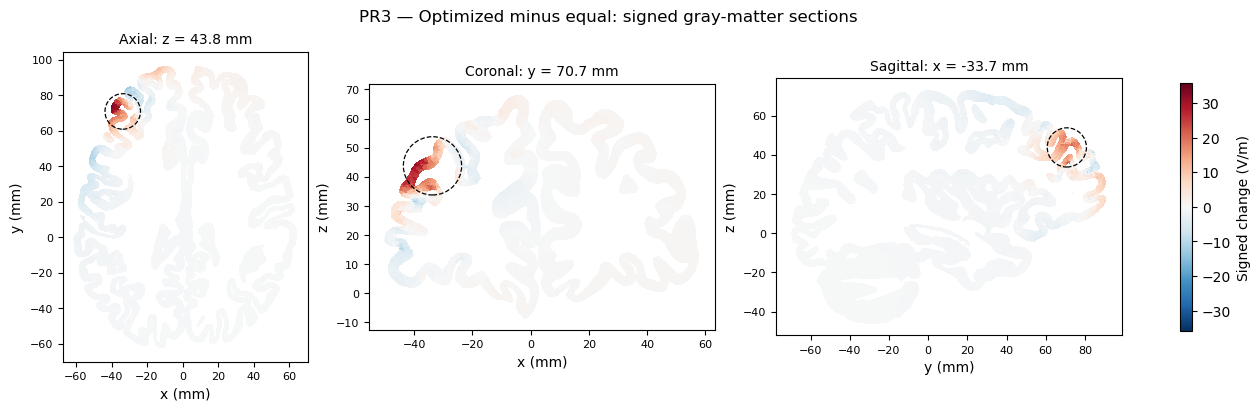

Matched slice exports complete: C:\Users\gothi\Documents\EEE488_CAPSTONE\ricn\PR3\data\verified_20261126_182522_328531\combined_fields\PR3_standardized_figures


In [13]:
from matplotlib.collections import PolyCollection
from matplotlib.colors import Normalize, LinearSegmentedColormap
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Circle

# Exact plane/tetrahedron intersections, reused for every configuration.
# Use the same GM element subset and common ranges as the cortical maps.
gm_idx=np.flatnonzero((types==4)&(tags==2))
gm_vertices=xyz[conn[gm_idx,:4]-1]
plane_specs=[('Axial',2,0,1),('Coronal',1,0,2),('Sagittal',0,1,2)]
edges=((0,1),(0,2),(0,3),(1,2),(1,3),(2,3))
def section_geometry(axis,u,v):
    level=target_subject[axis]
    d=gm_vertices[:,:,axis]-level
    hits=np.flatnonzero((d.min(axis=1)<=0)&(d.max(axis=1)>=0))
    polygons=[]; element_ids=[]
    for j in hits:
        q=gm_vertices[j]; s=d[j]; points=[]
        for a,b in edges:
            if abs(s[a])<1e-9: points.append(q[a,[u,v]])
            if abs(s[b])<1e-9: points.append(q[b,[u,v]])
            if s[a]*s[b]<0:
                points.append((q[a]+s[a]/(s[a]-s[b])*(q[b]-q[a]))[[u,v]])
        if len(points)<3: continue
        p=np.unique(np.round(points,9),axis=0)
        if len(p)<3: continue
        c=p.mean(axis=0); p=p[np.argsort(np.arctan2(p[:,1]-c[1],p[:,0]-c[0]))]
        polygons.append(p); element_ids.append(gm_idx[j])
    assert polygons, f'Empty section {axis}'
    return polygons,np.asarray(element_ids)
sections={name:section_geometry(axis,u,v) for name,axis,u,v in plane_specs}
# Use Inferno for accessible black-based absolute slices.
# Numeric limits are identical to the cortical maps; palettes differ by renderer.
abs_cmap=plt.get_cmap('inferno'); diff_cmap=plt.get_cmap('RdBu_r')
abs_norm=Normalize(0,absolute_max); diff_norm=Normalize(-difference_limit,difference_limit)
slice_cases={k:magnitudes[k] for k in weights_by_case}
if 'D70' in output_files:
    dm=mesh_io.read_msh(str(output_files['D70']))
    if (np.array_equal(dm.elm.node_number_list,conn) and np.array_equal(dm.elm.elm_type,types) and np.array_equal(dm.elm.tag1,tags) and np.array_equal(dm.elm.elm_number,ref.elm.elm_number) and np.array_equal(dm.nodes.node_number,ref.nodes.node_number) and np.allclose(dm.nodes.node_coord,xyz,atol=1e-7,rtol=0)):
        slice_cases['D70']=np.asarray(next(f.value for f in dm.elmdata if f.field_name=='magnE')).ravel()
    else: print('D70 slice omitted: mesh does not match basis geometry.')
    del dm
names={'equal_budget':'Equal weights','optimized':'DE optimized','full_nominal':'Full nominal','P2_only':'P2 only','D70':'D70 benchmark','difference':'Optimized minus equal'}
def draw_section(ax,values,spec,norm,cmap):
    name,axis,u,v=spec; polys,ids=sections[name]
    coll=PolyCollection(polys,array=values[ids],cmap=cmap,norm=norm,edgecolors='none',antialiased=False)
    ax.add_collection(coll); ax.autoscale_view(); ax.set_aspect('equal')
    ax.add_patch(Circle(target_subject[[u,v]],ROI_RADIUS_MM,fill=False,edgecolor='black',linestyle='--',linewidth=.9))
    ax.set_xlabel('xyz'[u]+' (mm)'); ax.set_ylabel('xyz'[v]+' (mm)')
    ax.set_title(f'{name}: {"xyz"[axis]} = {target_subject[axis]:.1f} mm',fontsize=10)
    ax.tick_params(labelsize=8)
    return coll
fig,axs=plt.subplots(len(slice_cases),3,figsize=(13,3.5*len(slice_cases)),squeeze=False,layout='constrained')
for row,(key,values) in enumerate(slice_cases.items()):
    for ax,spec in zip(axs[row],plane_specs): draw_section(ax,values,spec,abs_norm,abs_cmap)
    axs[row,0].set_ylabel(names[key]+'\n'+axs[row,0].get_ylabel())
fig.colorbar(ScalarMappable(norm=abs_norm,cmap=abs_cmap),ax=axs.ravel().tolist(),label='|E| (V/m)',shrink=.8)
fig.suptitle('PR3 — Matched gray-matter sections (common absolute scale)')
fig.savefig(FIG_DIR/'PR3_matched_absolute_slices.png',dpi=300); plt.show(); plt.close(fig)
fig,axs=plt.subplots(1,3,figsize=(13,4),layout='constrained')
for ax,spec in zip(axs,plane_specs): draw_section(ax,delta,spec,diff_norm,diff_cmap)
fig.colorbar(ScalarMappable(norm=diff_norm,cmap=diff_cmap),ax=axs.tolist(),label='Signed change (V/m)',shrink=.8)
fig.suptitle('PR3 — Optimized minus equal: signed gray-matter sections')
fig.savefig(FIG_DIR/'PR3_signed_difference_slices.png',dpi=300); plt.show(); plt.close(fig)
for key,values in {**slice_cases,'difference':delta}.items():
    norm,cmap=(diff_norm,diff_cmap) if key=='difference' else (abs_norm,abs_cmap)
    fig,axs=plt.subplots(1,3,figsize=(13,4),layout='constrained')
    for ax,spec in zip(axs,plane_specs): draw_section(ax,values,spec,norm,cmap)
    fig.colorbar(ScalarMappable(norm=norm,cmap=cmap),ax=axs.tolist(),label='V/m',shrink=.8)
    fig.suptitle(names[key]); fig.savefig(FIG_DIR/f'PR3_slices_{key}.png',dpi=300); plt.close(fig)
print('Matched slice exports complete:',FIG_DIR)

## 13 — Handoff to Aaron
Provide the candidate CSV, optimization provenance JSON, target histograms, cortical comparison PNG and combined meshes. Report the fixed coefficient-sum constraint separately from the nominal energy proxy. The D70 numerical benchmark remains available even without its optional cortical panel. Verify visual appearance and optimization feasibility before using results in the report.

The slice panels are ready for editorial selection. Review visual appearance before marking the run approved.

Brandon, review the saved figures and numerical checks. Keep the complete timestamped output folder locally; select the CSV, provenance JSON, handoff JSON and report-ready PNGs for Aaron as needed. Do not upload duplicate large meshes unless requested. The handoff visual review remains PENDING until reviewed. The equal and optimized cases share coefficient sum, not energy; P2 alone is outside the equality constraint.


In [14]:
handoff={**record,'absolute_scale_V_per_m':[0,float(absolute_max)],'difference_scale_V_per_m':[-float(difference_limit),float(difference_limit)],'slice_center_subject_mm':target_subject.tolist(),'slice_tissue':'GM tetrahedra only','slice_cases':list(slice_cases),'cortical_cases':[c['key'] for c in CONFIGS],'visual_review':'PENDING','weights_by_case':{k:a.tolist() for k,a in weights_by_case.items()},'drive_MA_per_s':{k:(a*DIDT/1e6).tolist() for k,a in weights_by_case.items()},'nominal_energy_proxy_J':{k:float(ENERGY*np.sum(a*a)) for k,a in weights_by_case.items()},'exports':[str(p.relative_to(OUTPUT)) for p in sorted(OUTPUT.rglob('*')) if p.is_file()]}
(OUTPUT/'PR3_Brandon_handoff.json').write_text(json.dumps(handoff,indent=2),encoding='utf-8')
print('Aaron handoff:',OUTPUT/'PR3_Brandon_handoff.json')

Aaron handoff: C:\Users\gothi\Documents\EEE488_CAPSTONE\ricn\PR3\data\verified_20261126_182522_328531\PR3_Brandon_handoff.json
